<a href="https://colab.research.google.com/github/ThisumiWijesinghe/SMS_SPAM_DETECTION_ANN/blob/main/Neural_Netwrok.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1. Import Libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
import requests



#2. Download the dataset from UCI repository

In [2]:

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

# Check that the downloaded content is a ZIP file
assert response.content[:2] == b"PK", (
    "The downloaded file does not appear to be a ZIP archive."
)

with ZipFile(BytesIO(response.content)) as zip_file:
    print("Files available in the ZIP:")
    for filename in zip_file.namelist():
        print("-", filename)

    # Find the original message file
    dataset_file = next(
        name for name in zip_file.namelist()
        if Path(name).name == "SMSSpamCollection"
    )

    # Read the original tab-separated data
    with zip_file.open(dataset_file) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("\nDataset downloaded and loaded successfully!")
print("Dataset shape:", df.shape)


Files available in the ZIP:
- SMSSpamCollection
- readme

Dataset downloaded and loaded successfully!
Dataset shape: (5572, 2)


#3. Inspect the dataset

In [3]:

print("First 10 messages:")
display(df.head(10))

print("\nDataset dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()


First 10 messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...



Dataset dimensions:
Rows: 5572
Columns: 2

Column names:
['label', 'message']

Data types:
label      object
message    object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


#4. Check the target variables and class imbalance

Unique labels:
['ham' 'spam']

Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


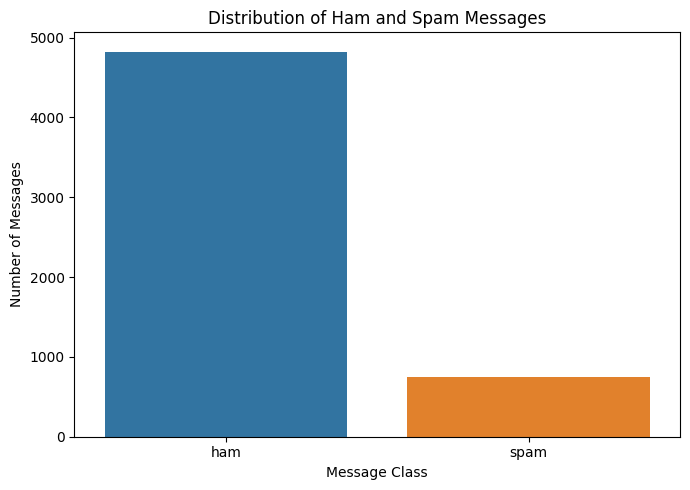

In [4]:
print("Unique labels:")
print(df["label"].unique())

label_counts = df["label"].value_counts()

print("\nClass counts:")
print(label_counts)

print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

# Visualise class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label", hue="label", legend=False)

plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Class")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


#5. Check the missing values , duplicates and data quality

In [5]:

# Cell 5: Data quality checks

print("Missing values per column:")
print(df.isnull().sum())

print("\nCompletely duplicated rows:")
print(df.duplicated().sum())

print("\nDuplicated message texts:")
print(df["message"].duplicated().sum())

print("\nEmpty or whitespace-only messages:")
print(df["message"].str.strip().eq("").sum())

print("\nUnexpected labels:")
print(sorted(set(df["label"].unique()) - {"ham", "spam"}))


Missing values per column:
label      0
message    0
dtype: int64

Completely duplicated rows:
403

Duplicated message texts:
403

Empty or whitespace-only messages:
0

Unexpected labels:
[]


#6. Find out the length of mesage for class

In [7]:

df["character_count"] = df["message"].str.len()

df["word_count"] = df["message"].apply(
    lambda message: len(message.split())
)

print("Message length statistics:")
display(
    df.groupby("label")[["character_count", "word_count"]]
      .describe()
      .round(2)
)


Message length statistics:


character_count                                                   \
                count    mean    std   min    25%    50%    75%    max   
label                                                                    
ham            4825.0   71.48  58.44   2.0   33.0   52.0   93.0  910.0   
spam            747.0  138.67  28.87  13.0  133.0  149.0  157.0  223.0   

      word_count                                              
           count   mean    std  min   25%   50%   75%    max  
label                                                         
ham       4825.0  14.31  11.52  1.0   7.0  11.0  19.0  171.0  
spam       747.0  23.91   5.78  2.0  22.0  25.0  28.0   35.0

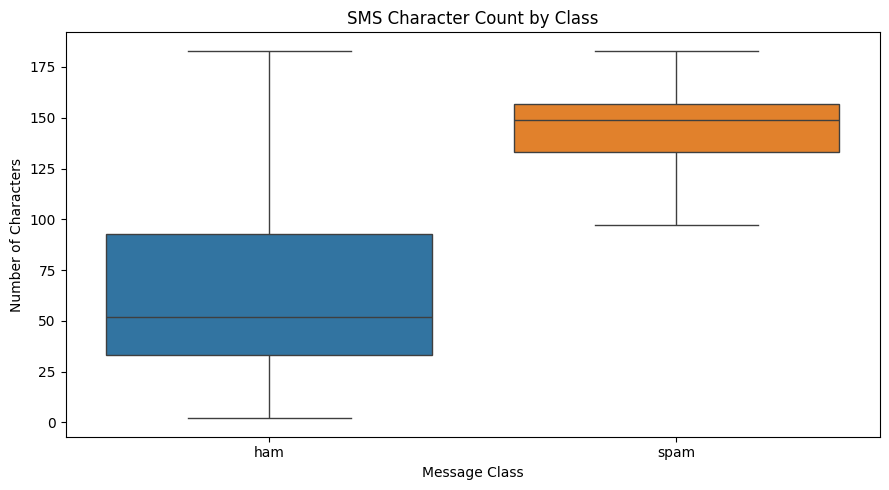

In [15]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="label",
    y="character_count",
    hue="label",
    legend=False,
    showfliers=False
)

plt.title("SMS Character Count by Class")
plt.xlabel("Message Class")
plt.ylabel("Number of Characters")
plt.tight_layout()
plt.show()

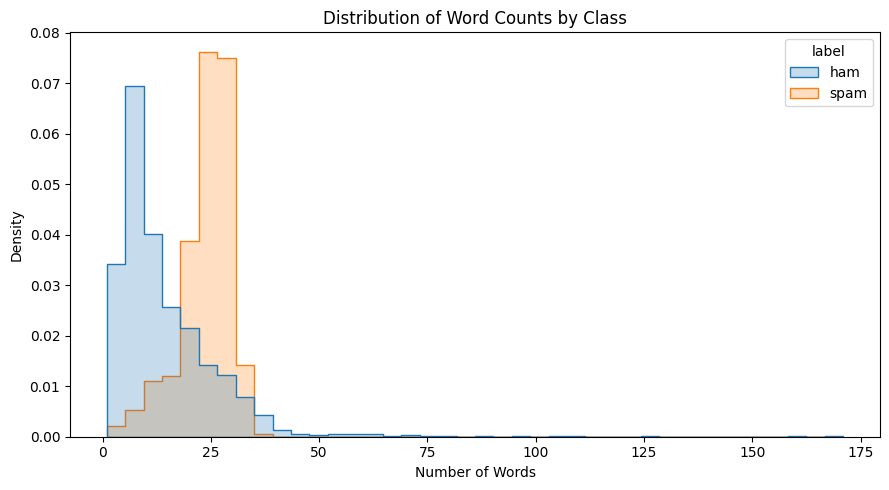

In [13]:

#Compare word counts by class

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="word_count",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Distribution of Word Counts by Class")
plt.xlabel("Number of Words")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [10]:

print("Examples of legitimate messages (ham):")
display(
    df.loc[df["label"] == "ham", ["label", "message"]].head(5)
)

print("\nExamples of spam messages:")
display(
    df.loc[df["label"] == "spam", ["label", "message"]].head(5)
)


Examples of legitimate messages (ham):


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
6,ham,Even my brother is not like to speak with me. ...



Examples of spam messages:


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
5,spam,FreeMsg Hey there darling it's been 3 week's n...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."


#7. Save the Loaded dataset

In [14]:

# Save the loaded dataset and exploratory copy

output_dir = Path("/content/sms_spam_project")
output_dir.mkdir(parents=True, exist_ok=True)

# Preserve the original two columns separately
df[["label", "message"]].to_csv(
    output_dir / "sms_spam_original.csv",
    index=False
)

# Save the exploratory version with message lengths
df.to_csv(
    output_dir / "sms_spam_exploration.csv",
    index=False
)

print("Files saved to:", output_dir)
print("\nSaved files:")
for path in sorted(output_dir.iterdir()):
    print(path.name, "-", path.stat().st_size, "bytes")



# Final data quality summary

print("Total messages:", len(df))
print("Missing values:", df[["label", "message"]].isnull().sum().sum())
print("Duplicate rows:", df[["label", "message"]].duplicated().sum())
print("Empty messages:", df["message"].str.strip().eq("").sum())
print("Class counts:\n", df["label"].value_counts())



Files saved to: /content/sms_spam_project

Saved files:
sms_spam_exploration.csv - 513837 bytes
sms_spam_original.csv - 480806 bytes
Total messages: 5572
Missing values: 0
Duplicate rows: 403
Empty messages: 0
Class counts:
 label
ham     4825
spam     747
Name: count, dtype: int64


# Step 2 : 1. Preprocessing Part

In [16]:

# Clean the dataset and create train/validation/test sets

from sklearn.model_selection import train_test_split

# 1. Keep only the original columns
data = df[["label", "message"]].copy()

print("Original dataset size:", len(data))

# 2. Remove exact duplicate rows
data = data.drop_duplicates(subset=["label", "message"]).reset_index(drop=True)

print("Dataset size after removing exact duplicates:", len(data))
print("Duplicates remaining:", data.duplicated(subset=["label", "message"]).sum())

# 3. Encode labels: ham = 0, spam = 1
data["target"] = data["label"].map({"ham": 0, "spam": 1})

# Verify the encoding
print("\nLabel mapping:")
print({"ham": 0, "spam": 1})

print("\nClass counts after cleaning:")
print(data["label"].value_counts())

# 4. Separate text and target
X = data["message"]
y = data["target"]

# 5. Split off 15% for the final test set
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# 6. Split the remaining 85% into training and validation.
# This gives approximately 70% train, 15% validation, 15% test.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.1764705882,
    random_state=42,
    stratify=y_train_val
)

# 7. Display split sizes
print("\nSplit sizes:")
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))
print("Total:", len(X_train) + len(X_val) + len(X_test))

# 8. Check class proportions in each split
split_summary = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Testing": y_test.value_counts(normalize=True)
}).T.rename(columns={0: "ham proportion", 1: "spam proportion"})

print("\nClass proportions in each split:")
display((split_summary * 100).round(2))


Original dataset size: 5572
Dataset size after removing exact duplicates: 5169
Duplicates remaining: 0

Label mapping:
{'ham': 0, 'spam': 1}

Class counts after cleaning:
label
ham     4516
spam     653
Name: count, dtype: int64

Split sizes:
Training: 3617
Validation: 776
Testing: 776
Total: 5169

Class proportions in each split:


target,ham proportion,spam proportion
Training,87.37,12.63
Validation,87.37,12.63
Testing,87.37,12.63


#2. Save cleaned data and split information

In [17]:


from pathlib import Path
import json
import platform
import pandas as pd
import sklearn

# Create project folder
output_dir = Path("/content/sms_spam_project")
output_dir.mkdir(parents=True, exist_ok=True)

# Check that the existing splits are available
assert len(X_train) == len(y_train), "Training data and labels do not match"
assert len(X_val) == len(y_val), "Validation data and labels do not match"
assert len(X_test) == len(y_test), "Testing data and labels do not match"

# Check that all samples are accounted for
assert len(X_train) + len(X_val) + len(X_test) == len(data)

# Check for overlapping row indices between splits
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

# Save cleaned dataset
data.to_csv(output_dir / "sms_spam_cleaned.csv", index=False)

# Save the indices used for each split
pd.Series(X_train.index, name="row_index").to_csv(
    output_dir / "train_indices.csv", index=False
)
pd.Series(X_val.index, name="row_index").to_csv(
    output_dir / "validation_indices.csv", index=False
)
pd.Series(X_test.index, name="row_index").to_csv(
    output_dir / "test_indices.csv", index=False
)

# Save a combined split manifest
split_manifest = pd.concat([
    pd.DataFrame({"row_index": X_train.index, "split": "train"}),
    pd.DataFrame({"row_index": X_val.index, "split": "validation"}),
    pd.DataFrame({"row_index": X_test.index, "split": "test"})
], ignore_index=True)

split_manifest.to_csv(
    output_dir / "split_manifest.csv", index=False
)

# Save settings for reproducibility
settings = {
    "dataset": "UCI SMS Spam Collection",
    "source": "https://archive.ics.uci.edu/dataset/228/sms+spam+collection",
    "original_rows": 5572,
    "cleaned_rows": len(data),
    "duplicates_removed": 403,
    "label_mapping": {"ham": 0, "spam": 1},
    "split_sizes": {
        "train": len(X_train),
        "validation": len(X_val),
        "test": len(X_test)
    },
    "split_method": "Stratified train_test_split",
    "random_state": 42,
    "python_version": platform.python_version(),
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__
}

with open(output_dir / "experiment_settings.json", "w") as f:
    json.dump(settings, f, indent=4)

print("Data and split information saved successfully.")
print("Project folder:", output_dir)
print("\nSaved files:")
for file_path in sorted(output_dir.iterdir()):
    print("-", file_path.name)

Data and split information saved successfully.
Project folder: /content/sms_spam_project

Saved files:
- experiment_settings.json
- sms_spam_cleaned.csv
- sms_spam_exploration.csv
- sms_spam_original.csv
- split_manifest.csv
- test_indices.csv
- train_indices.csv
- validation_indices.csv


# 3. Text preprocessing

In [18]:
#Text preprocessing using TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer
from pathlib import Path
import joblib

# Create the vectorizer
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

# Fit ONLY on the training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform validation and test messages using the fitted vectorizer
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF preprocessing completed.")
print("Training feature shape:", X_train_tfidf.shape)
print("Validation feature shape:", X_val_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)
print("Number of vocabulary terms:", len(tfidf.vocabulary_))

# Save the fitted vectorizer for reproducibility
joblib.dump(tfidf, output_dir / "tfidf_vectorizer.joblib")

TF-IDF preprocessing completed.
Training feature shape: (3617, 10000)
Validation feature shape: (776, 10000)
Testing feature shape: (776, 10000)
Number of vocabulary terms: 10000


['/content/sms_spam_project/tfidf_vectorizer.joblib']

#4. Train a baseline machine-learning model

Validation Results — Logistic Regression
-----------------------------------------
Accuracy:  0.9601
Precision: 1.0000
Recall:    0.6837
F1-score:  0.8121

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       678
        Spam       1.00      0.68      0.81        98

    accuracy                           0.96       776
   macro avg       0.98      0.84      0.89       776
weighted avg       0.96      0.96      0.96       776



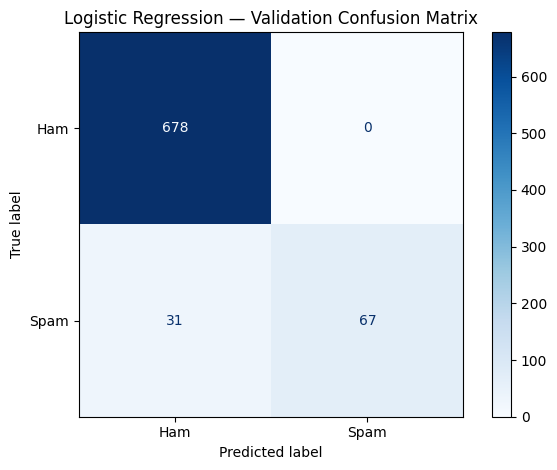

['/content/sms_spam_project/logistic_regression_baseline.joblib']

In [19]:
# Step 3: Train a Logistic Regression baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import json

# Train on training data only
baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight=None,
    random_state=42
)

baseline_model.fit(X_train_tfidf, y_train)

# Evaluate on the validation set first
val_predictions = baseline_model.predict(X_val_tfidf)

print("Validation Results — Logistic Regression")
print("-----------------------------------------")
print(f"Accuracy:  {accuracy_score(y_val, val_predictions):.4f}")
print(f"Precision: {precision_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, val_predictions, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, val_predictions, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

# Plot validation confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=[0, 1],
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Save the trained baseline model
joblib.dump(baseline_model, output_dir / "logistic_regression_baseline.joblib")

#5. save baseline validation results

In [20]:

baseline_metrics = {
    "model": "Logistic Regression",
    "evaluation_set": "validation",
    "accuracy": float(accuracy_score(y_val, val_predictions)),
    "precision_spam": float(
        precision_score(y_val, val_predictions, zero_division=0)
    ),
    "recall_spam": float(
        recall_score(y_val, val_predictions, zero_division=0)
    ),
    "f1_spam": float(
        f1_score(y_val, val_predictions, zero_division=0)
    )
}

with open(output_dir / "baseline_validation_metrics.json", "w") as f:
    json.dump(baseline_metrics, f, indent=4)

print("Baseline validation metrics saved.")
print(json.dumps(baseline_metrics, indent=4))

Baseline validation metrics saved.
{
    "model": "Logistic Regression",
    "evaluation_set": "validation",
    "accuracy": 0.9600515463917526,
    "precision_spam": 1.0,
    "recall_spam": 0.6836734693877551,
    "f1_spam": 0.8121212121212121
}
